# BWI Instagram & Meta Ads Analytics

*By Wira Atmaja*

Business Wisdom Institute (BWI) runs organic Instagram content to build audience, and paid Meta ad campaigns to convert that audience into seminar leads. This notebook cleans and analyzes 636 Instagram posts (May 2022–Feb 2025) and 13 Meta ad campaigns (Feb–Aug 2026) to answer two questions:

1. *Which organic content actually earns engagement, once audience size is accounted for?*
2. *Does the organic content history support or complicate what BWI's paid-ads reports concluded about creative performance?*


**Tools:** Python (*pandas, matplotlib, statsmodels*)

## 1. Import & Data Loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.listdir('/content/drive/MyDrive/BWI_Folders')

['Content_Analytics_2022-FEB2025.xlsx',
 'Meta_ads_data.xlsx',
 'BWI_Instagram_Ads_Analysis.ipynb']

## 2. Data Cleaning

The raw Excel file has a 3-row merged header, mixed date formats, and very messy content type column with roughly 30 different spellings, abbreviations and multi-tagged values for what turns out to be 11 real categories.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import datetime

raw = pd.read_excel('/content/drive/MyDrive/BWI_Folders/Content_Analytics_2022-FEB2025.xlsx', header=None)

# Keep only rows with a genuinely parseable date in column 1 (not a weekday-label filter,
# which silently dropped 107 real rows from May-Nov 2022 in an earlier version of this pipeline)
is_data_row = raw[1].apply(lambda x: pd.notna(pd.to_datetime(x, errors='coerce')))
data = raw[is_data_row].copy()

# The header spans 3 raw rows with merged cells; forward-fill the top two rows to
# recover the repeated group labels (e.g. "Facebook", "Instagram"), then join with the
# per-metric row underneath
header_raw = raw.iloc[1:4]
top_two = header_raw.iloc[0:2].ffill(axis=1)
bottom_one = header_raw.iloc[2:3]
fixed_header = pd.concat([top_two, bottom_one])
col_names = fixed_header.apply(lambda col: '_'.join([str(v) for v in col if pd.notna(v)]), axis=0)
data.columns = col_names

# Dates: one row has a typo ("31/08//2023"); errors='coerce' + explicit UTC handling
# avoids the tz-aware/tz-naive mixing error that a naive to_datetime() call throws
data['Date'] = data['Date'].apply(lambda x: pd.to_datetime(x, errors='coerce'))
data['Date'] = pd.to_datetime(data['Date'], utc=True).dt.tz_localize(None)

numeric_cols = [
    'Facebook_Reach', 'Facebook_Engagement_Reactions', 'Facebook_Engagement_Comments',
    'Facebook_Engagement_Shares', 'Facebook_Engagement_Saves', 'Facebook_Engagement in total',
    'Instagram_Reach', 'Instagram_Impression/\nViews', 'Instagram_Engagement_Likes',
    'Instagram_Engagement_Comments', 'Instagram_Engagement_Shares', 'Instagram_Engagement_Saves',
    'Instagram_Engagement in total', 'Instagram_Average watch time', 'Instagram_Duration'
]
data[numeric_cols] = data[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Format: the raw "Slides" column holds either a slide count (Image post) or the literal
# string "Video"
data['Format'] = data['Slides'].apply(lambda x: 'Video' if x == 'Video' else 'Image')
data['Slides'] = pd.to_numeric(data['Slides'], errors='coerce')

data.shape

(636, 22)

### 2.1 Content Category Cleanup

Below are the raw categories before clean-up

In [ ]:
data['Type'].value_counts(dropna=False)

,count
Type,
PD,80
BI,66
Promotional,65
Greetings,62
Promotionals,57
Doc - Portfolio,44
BWI,43
Documentation,41
Educational,40


Several problems stacked on top of each other: the same category spelled multiple ways (`BI`, `IB`, `Business Insight`), casing differences (`documentations` vs `Documentations`), Indonesian labels next to English ones (`Dokumentasi`), posts tagged with two categories at once (`BI/Promotional`), and a handful of blanks. Fixing these one at a time and re-checking after each step is safer than one big regex that's hard to verify.

In [ ]:
data['Type'] = data['Type'].str.strip()
data['Type'].value_counts(dropna=False)

,count
Type,
PD,83
Promotional,69
BI,67
Greetings,63
Promotionals,57
Doc - Portfolio,44
BWI,43
Educational,41
Documentation,41


The bigger problem is the multi-tagged values (`BI/Promotional`, `Documentation, Review`). So i split on the separator and keep the first tag.

In [ ]:
# First attempt at this without a pd.notna() guard threw:
#   TypeError: expected string or bytes-like object, got 'float'
# — about 10 rows have a genuinely blank Type, so the guard passes those through as NaN
# instead of crashing on them
data['Type'] = data['Type'].apply(lambda x: re.split(r'[/,&]', x)[0].strip() if pd.notna(x) else x)
data['Type'].value_counts(dropna=False)

,count
Type,
PD,85
BI,75
Promotional,73
Greetings,63
Promotionals,57
Doc - Portfolio,44
Documentation,43
BWI,43
Educational,41


Down to the real abbreviations and spelling variants now. `BI`, `IB` and `Business Insight` are the same thing; `PD` is short for `Personal Development`; `Dokumentasi` and `Doc - Portfolio` are both `Documentation`; and a couple of entries just have an extra letter or different casing (`Promotionals`, `documentations`). So I fixed all of these onto one correct spelling.

In [ ]:
type_mapping = {
    'Promotionals': 'Promotional', 'Documentations': 'Documentation', 'documentations': 'Documentation',
    'Dokumentasi': 'Documentation', 'Doc - Portfolio': 'Documentation', 'PD': 'Personal Development',
    'BI': 'Business Insight', 'IB': 'Business Insight',
}
data['Type'] = data['Type'].replace(type_mapping)
data['Type'].value_counts(dropna=False)

,count
Type,
Promotional,130
Documentation,111
Personal Development,88
Business Insight,85
Greetings,63
BWI,43
Educational,41
Review,26
Entertainment,23


A few odd categories left, `Promotion` missing its final 's', `PD?` with a stray question mark, `???` for posts that were never actually categorised plus the NaNs left over from the multi-tag split. So to tackle this, I fold every remaining blank into an explicit `Uncategorized` label rather than leaving it as NaN, so it doesn't silently vanish from group-by counts later.

In [ ]:
data['Type'] = data['Type'].fillna('Uncategorized')
extra_mapping = {'Promotion': 'Promotional', 'PD?': 'Personal Development', '???': 'Uncategorized'}
data['Type'] = data['Type'].replace(extra_mapping)
data['Type'].value_counts()

,count
Type,
Promotional,131
Documentation,111
Personal Development,89
Business Insight,85
Greetings,63
BWI,43
Educational,41
Review,26
Entertainment,23


11 clean categories, every post accounted for. On to the numeric fields that need a similar sanity check.

### 2.2 Engagement Rate, checking for impossible values

Engagement Rate is defined as engagement ÷ reach. Before trusting it, I check whether any post impossibly has more engagement than the audience it supposedly reached

In [ ]:
data['Engagement_Rate'] = data['Instagram_Engagement in total'] / data['Instagram_Reach']

# Sanity check: can a post have more likes than the reach it recorded?
data[data['Instagram_Engagement_Likes'] > data['Instagram_Reach']][['Date', 'Content', 'Instagram_Reach', 'Instagram_Engagement_Likes']]

,Date,Content,Instagram_Reach,Instagram_Engagement_Likes
774,2022-08-31,3 quotes from Seneca,413.0,419.0


The post "3 quotes from Seneca" (Aug 2022) has more likes than reach, which is only possible if reach was logged incorrectly. Rather than guess at a corrected reach figure, the safest fix is to drop this one post's engagement rate from analysis while keeping the row itself.

In [ ]:
impossible = data['Instagram_Engagement_Likes'] > data['Instagram_Reach']
data.loc[impossible, 'Engagement_Rate'] = None

### 2.3 A malformed Day value

Day of week is used later in the regression, so I checked for anything that isn't a clean weekday name.

In [ ]:
data[data['Day'].astype(str).str.contains('\n', na=False)][['Date', 'Day', 'Content', 'Type']]

,Date,Day,Content,Type
313,2024-04-20 16:24:00,Friday\nSaturday,Movie discussions: The Intern,Entertainment


One row literally has `"Friday\nSaturday"` as its Day value. Both days typed into the same cell. The post's actual date settles which one is correct.

In [ ]:
pd.Timestamp('2024-04-20').day_name()

'Saturday'

In [ ]:
data.loc[data['Day'] == 'Friday\nSaturday', 'Day'] = 'Saturday'

data['YearMonth'] = data['Date'].dt.to_period('M')
data.shape

(636, 24)

Summary of Cleanup

- **Missing months recovered:** an earlier weekday-based row filter silently dropped 107 real posts from May–Nov 2022 (rows with a valid date but a blank Day field). Filtering on date validity instead recovered the full 636-row history.
- **One impossible data point excluded:** the Seneca post recorded more Instagram likes than reach (an internal logging error). Its engagement rate is excluded above; the post itself is kept.
- **Categories are all cleaned up**


## 3. Content Type & Format Performance

In [ ]:
type_stats = data.groupby('Type')['Engagement_Rate'].agg(['mean', 'count']).sort_values('mean', ascending=False)
type_stats['mean_pct'] = (type_stats['mean'] * 100).round(2)
type_stats

,mean,count,mean_pct
Type,,,
Documentation,0.065650,109,6.56
Uncategorized,0.057424,11,5.74
Review,0.056123,26,5.61
BWI,0.052353,43,5.24
Educational,0.051817,40,5.18
Greetings,0.049789,63,4.98
Personal Development,0.047673,88,4.77
Conversational,0.046947,13,4.69
Entertainment,0.043085,22,4.31


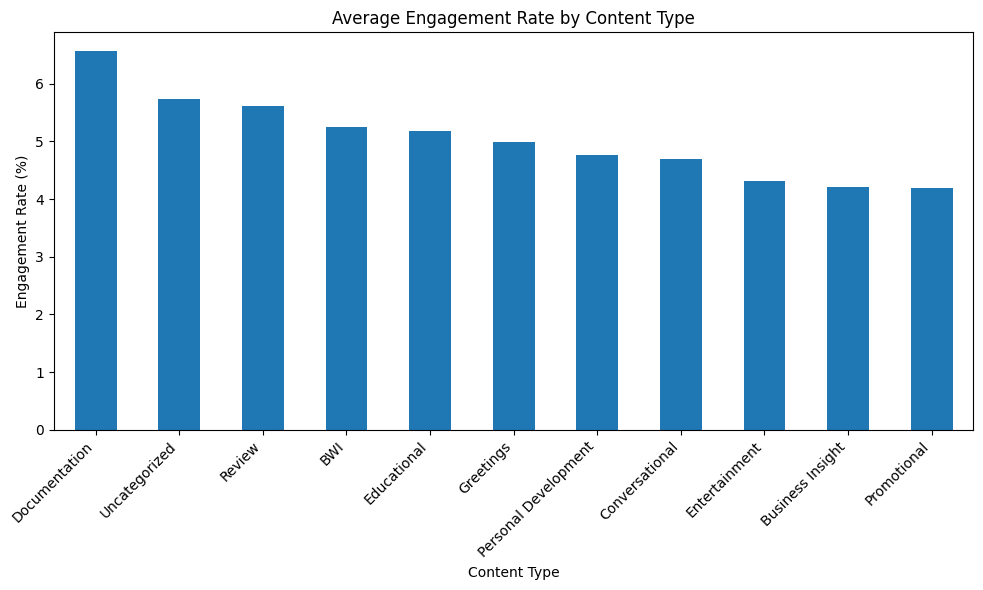

In [ ]:
type_stats['mean_pct'].plot(kind='bar', figsize=(10, 6))
plt.title('Average Engagement Rate by Content Type')
plt.ylabel('Engagement Rate (%)')
plt.xlabel('Content Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
data.groupby('Format')['Engagement_Rate'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
Format,,
Video,0.050529,172
Image,0.049809,456


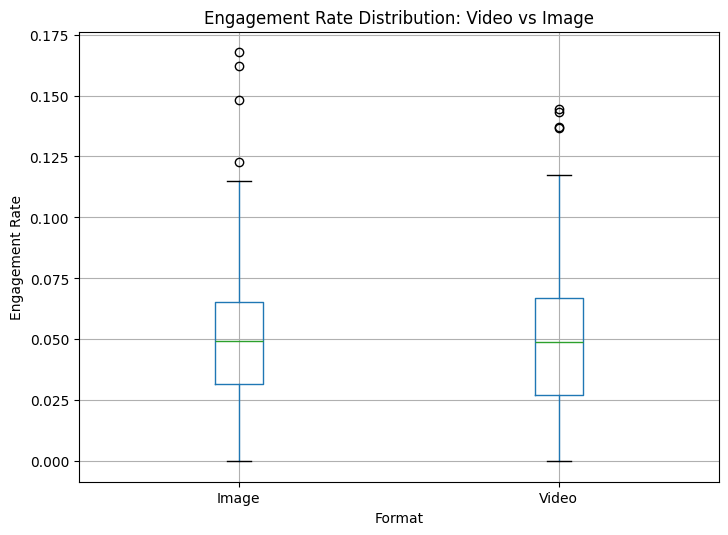

In [ ]:
data.boxplot(column='Engagement_Rate', by='Format', figsize=(8, 6))
plt.title('Engagement Rate Distribution: Video vs Image')
plt.suptitle('')
plt.ylabel('Engagement Rate')
plt.show()

## 4. Engagement Rate Trend, May 2022 - Feb 2025

In [ ]:
monthly_trend = (data.groupby('YearMonth')['Engagement_Rate'].mean() * 100).round(2)
monthly_trend

,Engagement_Rate
YearMonth,
2022-05,4.87
2022-06,5.80
2022-07,5.57
2022-08,5.79
2022-09,4.92
2022-10,5.10
2022-11,5.44
2022-12,5.54
2023-01,5.57


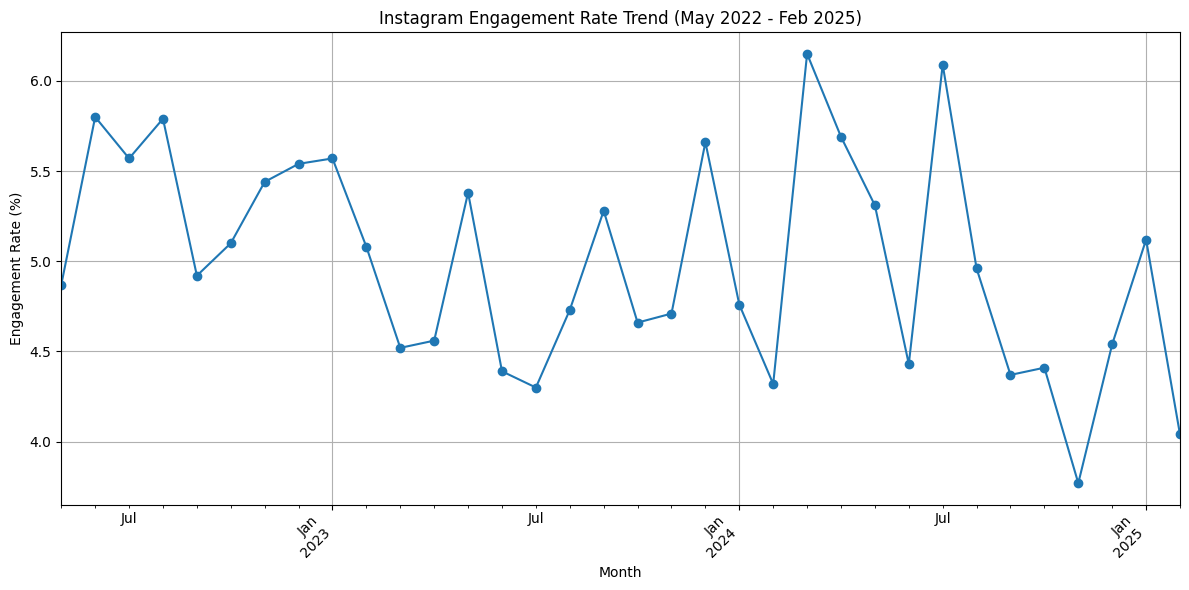

In [ ]:
monthly_trend.plot(kind='line', figsize=(12, 6), marker='o')
plt.title('Instagram Engagement Rate Trend (May 2022 - Feb 2025)')
plt.ylabel('Engagement Rate (%)')
plt.xlabel('Month')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Reach vs. Engagement Rate by Content Type

Promotional and Business Insight content earns the highest average *reach*, but (as seen in section 3) the lowest engagement *rate*

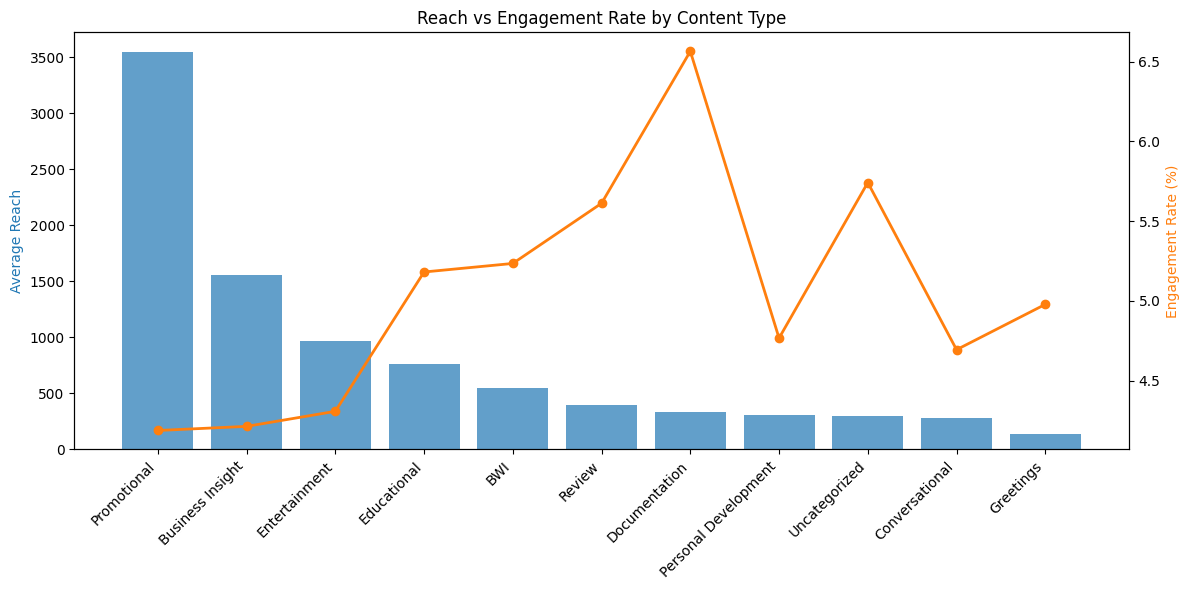

In [ ]:
type_reach = data.groupby('Type')['Instagram_Reach'].mean().sort_values(ascending=False)
type_rate = data.groupby('Type')['Engagement_Rate'].mean().reindex(type_reach.index) * 100

fig, ax1 = plt.subplots(figsize=(12, 6))
x = range(len(type_reach))
ax1.bar(x, type_reach.values, color='tab:blue', alpha=0.7, label='Reach')
ax1.set_ylabel('Average Reach', color='tab:blue')
ax1.set_xticks(x)
ax1.set_xticklabels(type_reach.index, rotation=45, ha='right')
ax2 = ax1.twinx()
ax2.plot(x, type_rate.values, color='tab:orange', marker='o', linewidth=2, label='Engagement Rate')
ax2.set_ylabel('Engagement Rate (%)', color='tab:orange')
plt.title('Reach vs Engagement Rate by Content Type')
fig.tight_layout()
plt.show()

## 6. Meta Ads: Organic vs. Paid Bridge

BWI's paid campaigns are almost entirely video (12 of 13)

In [ ]:
ads = pd.read_excel('/content/drive/MyDrive/BWI_Folders/Meta_ads_data.xlsx')
ads.columns.tolist()

['Reporting starts',
 'Reporting ends',
 'Campaign name',
 'Campaign delivery',
 'Attribution setting',
 'Results',
 'Result indicator',
 'Reach',
 'Frequency',
 'Cost per results',
 'Ad set budget',
 'Ad set budget type',
 'Amount spent (IDR)',
 'Ends',
 'Impressions',
 'CPM (cost per 1,000 impressions) (IDR)',
 'Link clicks',
 'shop_clicks',
 'CPC (cost per link click) (IDR)',
 'CTR (link click-through rate)',
 'Clicks (all)',
 'CTR (all)',
 'CPC (all) (IDR)',
 'Landing page views',
 'Cost per landing page view (IDR)',
 'Starts',
 'ThruPlays',
 'Cost per ThruPlay (IDR)',
 'Results ROAS',
 'Result ROAS indicator',
 'Result rate',
 'Messaging conversations started',
 '3-second video plays rate per impressions',
 'Purchases',
 'Checkouts initiated',
 'Leads',
 'Adds to cart',
 'Results (initial)',
 'Results (initial) indicator']

In [ ]:
ads_clean = ads[[
    'Campaign name', 'Reach', 'Impressions', 'Amount spent (IDR)',
    'CTR (link click-through rate)', 'Cost per results', 'Results',
    'Leads', 'Messaging conversations started', 'ThruPlays',
    '3-second video plays rate per impressions'
]].copy()

ads_clean['Format'] = ads_clean['ThruPlays'].apply(lambda x: 'Video' if pd.notna(x) and x > 0 else 'Image')
ads_clean['Objective'] = ads_clean['Campaign name'].apply(
    lambda x: 'Awareness' if 'AWAR' in x.upper() else ('Sales' if 'SALES' in x.upper() else 'Leads')
)
ads_clean[['Campaign name', 'Objective', 'Format', 'Reach', 'Results', 'Cost per results']]

,Campaign name,Objective,Format,Reach,Results,Cost per results
0,Publik Februari\nLEAD-SMART-PUBLIC-SPEAKER_040...,Leads,Video,294908,265.0,6769.690566
1,Publik Maret\nLEAD-STORYTELLING_03032026,Leads,Video,10233,37.0,21990.378378
2,Publik Maret\nSALES-STORYTELLING_04032026,Sales,Video,1870,NaN,NaN
3,Publik Maret\nLEAD-STORYTELLING_16032026,Leads,Video,60867,60.0,9910.183333
4,Publik Maret\nLEAD-STORYTELLING_26032026,Leads,Video,533,NaN,NaN
5,Publik Maret\nSALES-STORYTELLING_27032026,Sales,Video,3252,2.0,86807.000000
6,Publik April\nLEADS_HRPLAYBOOK_06042026,Leads,Video,314,NaN,NaN
7,Publik April\nSALES_HRPLAYBOOK_07042026,Sales,Video,8624,NaN,NaN
8,Publik Mei \nLEADS_SEMINAR-PUBLIK_27042026,Leads,Video,20806,26.0,97561.500000
9,Publik Malaysia (di luar jadwal bulanan)\nAWAR...,Awareness,Image,411571,411571.0,2428.640502


In [ ]:
# Isolate the Leads-objective campaigns (9 of 13) and drop the 3 with no completed results yet
leads_campaigns = ads_clean[ads_clean['Objective'] == 'Leads'].copy()
leads_valid = leads_campaigns.dropna(subset=['Cost per results']).copy()
leads_valid['Month'] = leads_valid['Campaign name'].str.extract(r'Publik (\w+)')

# 'Reporting starts' loads as a mix of datetime and string values across some pipeline
# re-runs; forcing it through pd.to_datetime before sorting avoids a str-vs-datetime
# comparison error
ads['Reporting starts'] = pd.to_datetime(ads['Reporting starts'], errors='coerce')
leads_valid = leads_valid.merge(ads[['Campaign name', 'Reporting starts']], on='Campaign name', how='left')
leads_valid = leads_valid.sort_values('Reporting starts')
leads_valid[['Campaign name', 'Month', 'Reporting starts', 'Amount spent (IDR)', 'Results', 'Cost per results']]

,Campaign name,Month,Reporting starts,Amount spent (IDR),Results,Cost per results
0,Publik Februari\nLEAD-SMART-PUBLIC-SPEAKER_040...,Februari,2026-02-04,1793968,265.0,6769.690566
1,Publik Maret\nLEAD-STORYTELLING_03032026,Maret,2026-03-03,813644,37.0,21990.378378
2,Publik Maret\nLEAD-STORYTELLING_16032026,Maret,2026-03-03,594611,60.0,9910.183333
3,Publik Mei \nLEADS_SEMINAR-PUBLIK_27042026,Mei,2026-04-27,2536599,26.0,97561.500000
4,Publik Juni\nLEADS_SEMINAR-PUBLIK_27042026,Juni,2026-05-22,2549719,15.0,169981.266700
5,Publik Agustus\nLEADS_SEMINAR-PUBLIK_27042026,Agustus,2026-07-16,2654271,22.0,120648.681800


Two campaigns both start in March (both dated 2026-03-03). genuinely concurrent, not sequential relaunches. Merging same-month campaigns for the chart requires summing spend and results *before* dividing (a weighted average), not averaging the two campaigns' cost-per-result figures directly, which would overstate the cheaper campaign's influence.

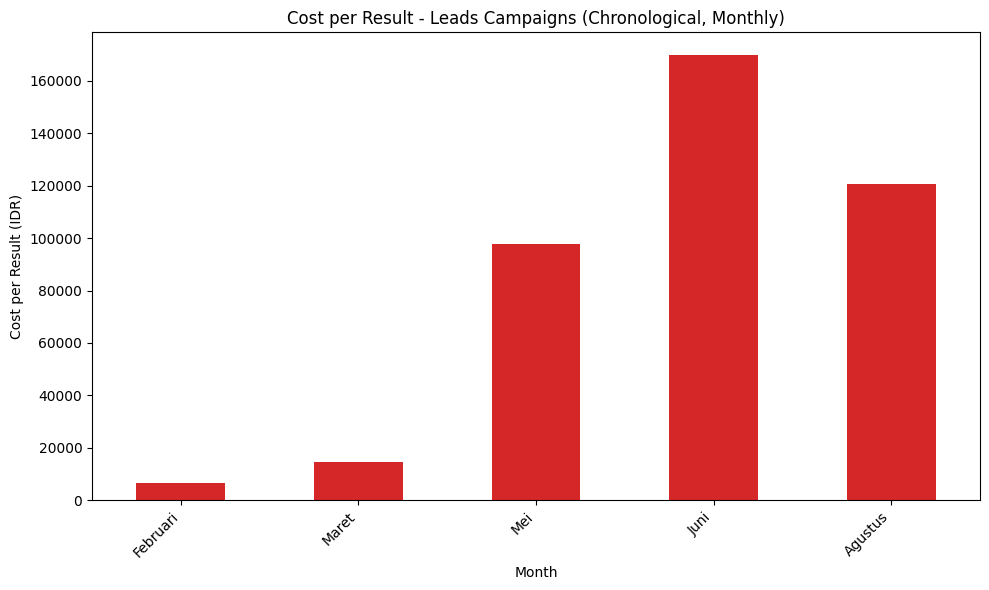

In [ ]:
monthly_ads = leads_valid.groupby('Month').agg(
    total_spend=('Amount spent (IDR)', 'sum'),
    total_results=('Results', 'sum'),
    first_date=('Reporting starts', 'min')
).reset_index()

monthly_ads['Cost_per_Result'] = monthly_ads['total_spend'] / monthly_ads['total_results']
monthly_ads = monthly_ads.sort_values('first_date')

monthly_ads.plot(x='Month', y='Cost_per_Result', kind='bar', figsize=(10, 6), legend=False, color='tab:red')
plt.title('Cost per Result - Leads Campaigns (Chronological, Monthly)')
plt.ylabel('Cost per Result (IDR)')
plt.xlabel('Month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Cost per lead rose from roughly Rp6,770 in February to a peak of Rp169,981 in June (about 25x) before easing to Rp120,649 in August. This lines up with issues BWI's own agency reports flagged: campaigns repeatedly restarting Meta's "learning phase", and tracking discrepancies between Meta and BWI's internal GASS system.

## 7. Predictive Model: What Drives Engagement Rate?

An OLS regression of Engagement Rate on content Type, Format and Day of week, controlling for all three at once.

In [ ]:
model_data = data[['Type', 'Format', 'Day', 'Engagement_Rate']].dropna()
model_encoded = pd.get_dummies(model_data, columns=['Type', 'Format', 'Day'], drop_first=True)
model_encoded.shape

(522, 18)

In [ ]:
import statsmodels.api as sm

X = model_encoded.drop(columns='Engagement_Rate')
y = model_encoded['Engagement_Rate']

X = X.astype(int)          # convert True/False dummies to 1/0
X = sm.add_constant(X)     # adds the model's baseline/intercept term

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        Engagement_Rate   R-squared:                       0.143
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     4.960
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           5.52e-10
Time:                        02:47:37   Log-Likelihood:                 1191.7
No. Observations:                 522   AIC:                            -2347.
Df Residuals:                     504   BIC:                            -2271.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

**Reading the model:** R² = 0.143, modest, meaning most of what drives engagement is specific to each individual post rather than its category, format or posting day. Five factors are statistically significant (p < 0.05) against a baseline post (BWI-tagged, Image, posted Friday):

| Factor | Effect (pp) | p-value |
|---|---|---|
| Documentation | +1.20 | 0.017 |
| Saturday | +0.88 | 0.044 |
| Thursday | +0.83 | 0.043 |
| Promotional | -1.19 | 0.011 |
| Business Insight | -1.34 | 0.012 |

Format (Video vs. Image) is **not** statistically significant (p = 0.132) once Type and Day are controlled for, reinforcing that content type matters far more than format.

In [ ]:
data.to_csv('/content/drive/MyDrive/BWI_Folders/cleaned_content_data.csv', index=False)

In [ ]:
monthly_ads.to_csv('/content/drive/MyDrive/BWI_Folders/monthly_ads.csv', index=False)